In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc

In [2]:
df = pd.read_csv("CC GENERAL.csv")

print("Dataset shape:", df.shape)
print(df.head())

X = df.drop("CUST_ID", axis=1)
X = X.ffill()
X = X.bfill()

print("Missing values:", X.isnull().sum().sum())

Dataset shape: (8950, 18)
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.083333   
1         

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_normalized = normalize(X_scaled)

X_normalized = pd.DataFrame(X_normalized)

print("Preprocessing completed.")
print(X_normalized.head())

Preprocessing completed.
         0         1         2         3         4         5         6   \
0 -0.312038 -0.106331 -0.181129 -0.152156 -0.148808 -0.198985 -0.343796   
1  0.219928  0.037539 -0.131224 -0.099751 -0.127038  0.728177 -0.341439   
2  0.126684  0.146785 -0.030505  0.030851 -0.128792 -0.132251  0.359775   
3  0.020571 -0.426063  0.097223  0.228832 -0.190449 -0.154451 -0.424878   
4 -0.151630  0.218959 -0.195282 -0.146778 -0.192118 -0.197278 -0.428601   

         7         8         9         10        11        12        13  \
0 -0.289304 -0.301518 -0.287892 -0.202942 -0.217975 -0.409413 -0.225497   
1 -0.189662 -0.256269  0.160403  0.030762 -0.165387  0.192455  0.228782   
2  0.757449 -0.259805 -0.191342 -0.134881 -0.030888  0.234046 -0.108741   
3 -0.167299 -0.384185 -0.108474 -0.138062 -0.231084  0.346093 -0.250827   
4 -0.168765 -0.387551 -0.285424 -0.201202 -0.233109 -0.382671 -0.153993   

         14        15        16  
0 -0.130160 -0.224036  0.153753  
1  0.

In [4]:
pca = PCA(n_components=2, random_state=42)

X_principal = pca.fit_transform(X_normalized)
X_principal = pd.DataFrame(
    X_principal,
    columns=["P1", "P2"]
)

print(X_principal.head())

         P1        P2
0 -0.489949 -0.679976
1 -0.519099  0.544827
2  0.330633  0.268879
3 -0.481656 -0.097611
4 -0.563512 -0.482506


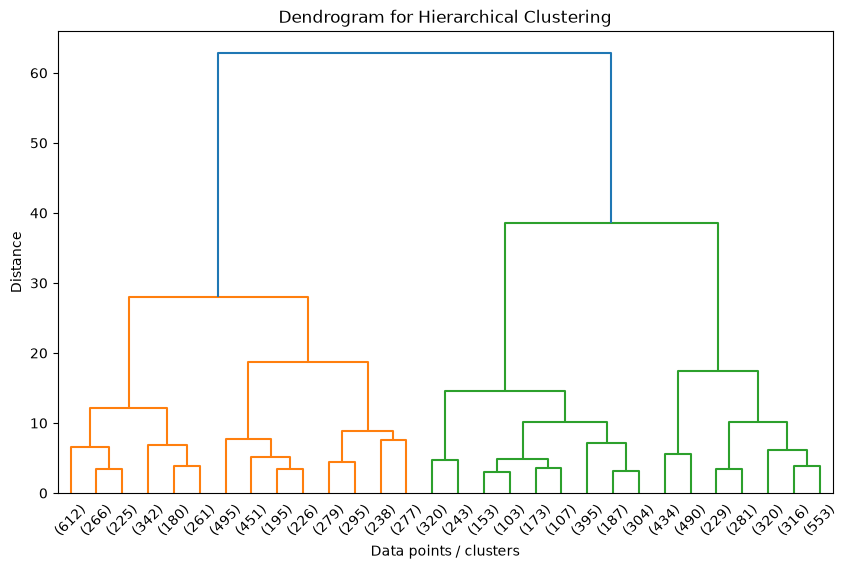

In [5]:
plt.figure(figsize=(10, 6))
plt.title("Dendrogram for Hierarchical Clustering")

dendrogram = shc.dendrogram(
    shc.linkage(X_principal, method="ward"),
    truncate_mode="lastp",
    p=30
)

plt.xlabel("Data points / clusters")
plt.ylabel("Distance")
plt.show()

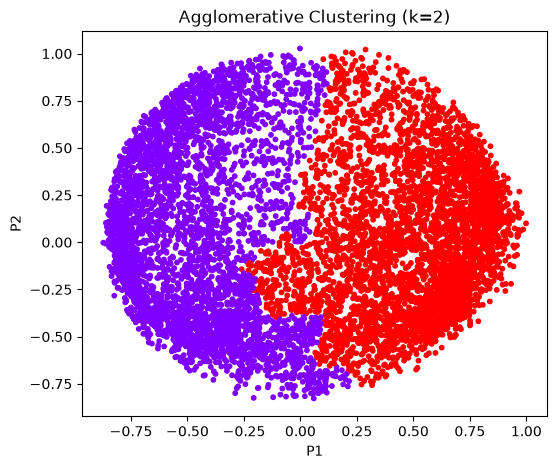

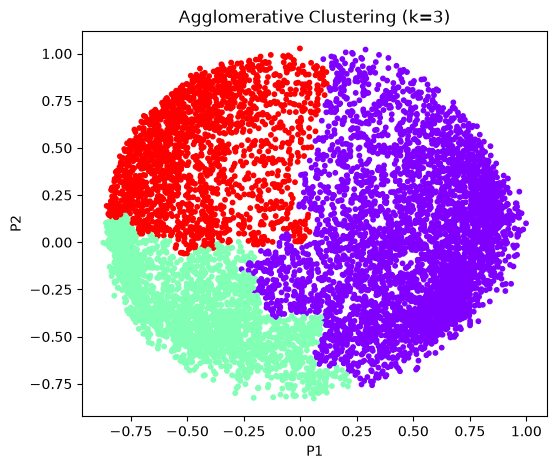

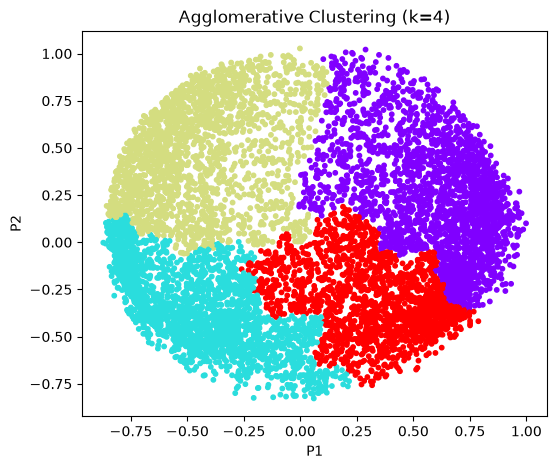

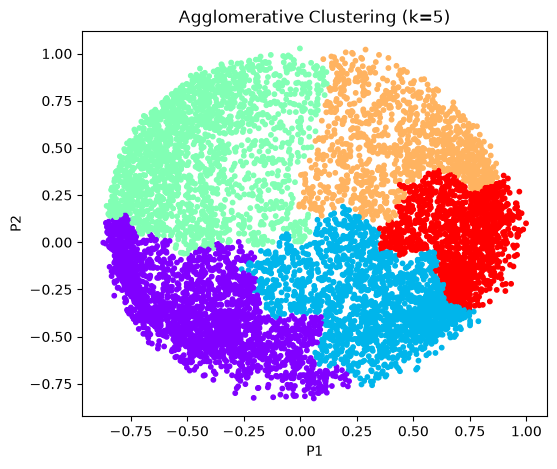

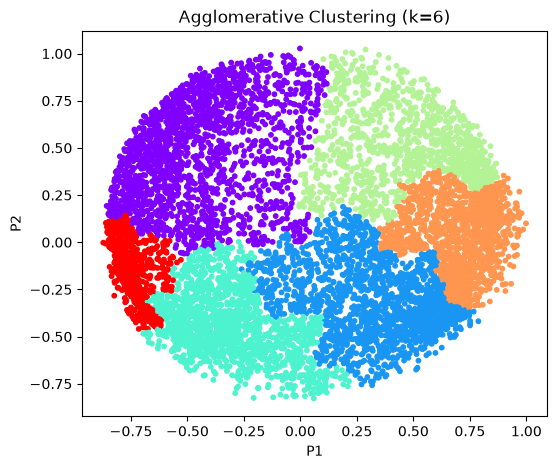

In [6]:
for k in [2, 3, 4, 5, 6]:
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_principal)

    plt.figure(figsize=(6, 5))
    plt.scatter(
        X_principal["P1"],
        X_principal["P2"],
        c=labels,
        cmap="rainbow",
        s=10
    )

    plt.title(f"Agglomerative Clustering (k={k})")
    plt.xlabel("P1")
    plt.ylabel("P2")
    plt.show()

k = 2, Silhouette Score = 0.4324
k = 3, Silhouette Score = 0.4278
k = 4, Silhouette Score = 0.3747
k = 5, Silhouette Score = 0.3551
k = 6, Silhouette Score = 0.3169


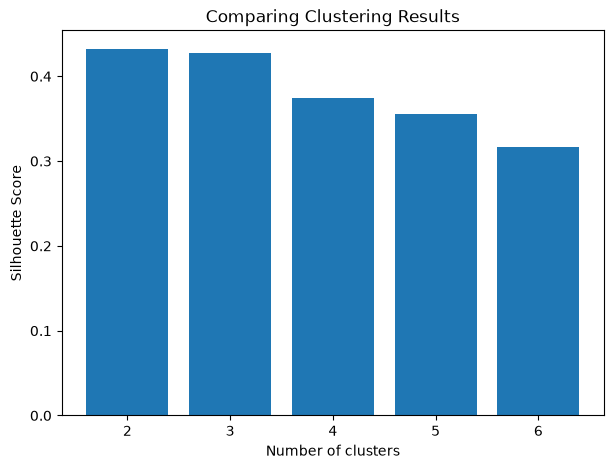

Best number of clusters: 2


In [7]:
k_values = [2, 3, 4, 5, 6]
silhouette_scores = []

for k in k_values:
    model = AgglomerativeClustering(n_clusters=k)
    labels = model.fit_predict(X_principal)

    score = silhouette_score(X_principal, labels)
    silhouette_scores.append(score)

    print(f"k = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(7, 5))
plt.bar(k_values, silhouette_scores)
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette Score")
plt.title("Comparing Clustering Results")
plt.show()

best_k = k_values[np.argmax(silhouette_scores)]
print("Best number of clusters:", best_k)